# Movie ratings: exploratory analysis with SQL

**Data:** a random sample of 500,000 ratings from [MovieLens 20M](https://grouplens.org/datasets/movielens/20m/) (GroupLens), stored in SQLite (`data/movies.db`). Every query below is plain SQL run through Python's `sqlite3`.

**Findings**

- **4.0 is the most common rating.** Half-star ratings appear only from February 2003, when MovieLens introduced them.
- **Among the 10 most-rated genres, Crime and Drama rate highest (3.68).** Horror is the lowest-rated genre overall (3.27). Niche genres rate higher still (Film-Noir 3.97, War 3.81): a selection effect, since people who seek out niche films tend to like them.
- **The Shawshank Redemption tops the films with at least 1,000 ratings (4.50).**
- **Older films rate higher** (1950s: 3.88, 2010s: 3.56). This is likely survivorship bias: the old films people still watch are the classics.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd

FIG_DIR = Path('../data')
con = sqlite3.connect('../data/movies.db')

def sql(query):
    return pd.read_sql_query(query, con)

# Chart style: light surface, hairline grid, one accent color
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, GRAY = '#2a78d6', '#b4b2a9'
mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'font.size': 10, 'legend.frameon': False, 'lines.linewidth': 2,
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
})

sql('''
    SELECT COUNT(*)                 AS ratings,
           COUNT(DISTINCT userId)   AS users,
           COUNT(DISTINCT movieId)  AS rated_movies,
           (SELECT COUNT(*) FROM movies) AS movies_in_catalog,
           MIN(timestamp)           AS first_rating,
           MAX(timestamp)           AS last_rating
    FROM ratings
''')

,ratings,users,rated_movies,movies_in_catalog,first_rating,last_rating
0,500000,106761,13152,27278,1995-01-09 11:46:44,2015-03-31 05:43:43


The sample was drawn rating by rating, so most users keep only a few of their ratings (median 3). That is fine for describing movies and genres, but not for modeling individual users. See `02_recommender.ipynb`.

## 1. How people rate

Mean rating 3.53; first half-star rating: 2003-02-18 22:17:19


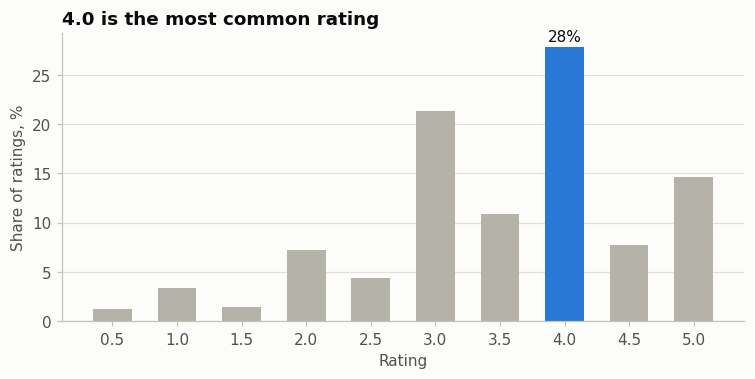

In [2]:
dist = sql('''
    SELECT rating, COUNT(*) AS n, ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM ratings), 1) AS pct
    FROM ratings
    GROUP BY rating
    ORDER BY rating
''')
first_half_star = sql('''
    SELECT MIN(timestamp) AS first_half_star FROM ratings WHERE rating IN (0.5, 1.5, 2.5, 3.5, 4.5)
''').iloc[0, 0]
print(f'Mean rating {sql("SELECT AVG(rating) FROM ratings").iloc[0, 0]:.2f}; first half-star rating: {first_half_star}')

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(dist['rating'].astype(str), dist['pct'], width=0.6,
       color=[BLUE if r == dist.loc[dist['n'].idxmax(), 'rating'] else GRAY for r in dist['rating']])
ax.annotate(f"{dist['pct'].max():.0f}%", (dist['n'].idxmax(), dist['pct'].max()),
            textcoords='offset points', xytext=(0, 4), ha='center', color=INK)
ax.set_xlabel('Rating')
ax.set_ylabel('Share of ratings, %')
ax.grid(axis='x', visible=False)
ax.set_title('4.0 is the most common rating')
plt.show()

## 2. Genres

A movie can have several genres (`Comedy|Romance`). A recursive CTE splits the pipe-separated list into one row per movie and genre.

In [3]:
genres = sql('''
    WITH RECURSIVE split(movieId, genre, rest) AS (
        SELECT movieId, '', genres || '|' FROM movies
        UNION ALL
        SELECT movieId,
               substr(rest, 1, instr(rest, '|') - 1),
               substr(rest, instr(rest, '|') + 1)
        FROM split
        WHERE rest <> ''
    ),
    movie_genres AS (
        SELECT movieId, genre FROM split WHERE genre NOT IN ('', '(no genres listed)')
    )
    SELECT g.genre,
           COUNT(*)                AS n_ratings,
           ROUND(AVG(r.rating), 3) AS avg_rating
    FROM ratings AS r
    JOIN movie_genres AS g USING (movieId)
    GROUP BY g.genre
    ORDER BY avg_rating DESC
''')
genres['top_10_by_ratings'] = genres['n_ratings'].rank(ascending=False) <= 10
genres

,genre,n_ratings,avg_rating,top_10_by_ratings
0,Film-Noir,5406,3.974,False
1,War,26212,3.813,False
2,Documentary,5923,3.771,False
3,Crime,82528,3.679,True
4,Drama,221722,3.678,True
5,IMAX,12407,3.666,False
6,Mystery,38908,3.665,False
7,Animation,28391,3.617,False
8,Musical,21602,3.567,False
9,Western,10813,3.564,False


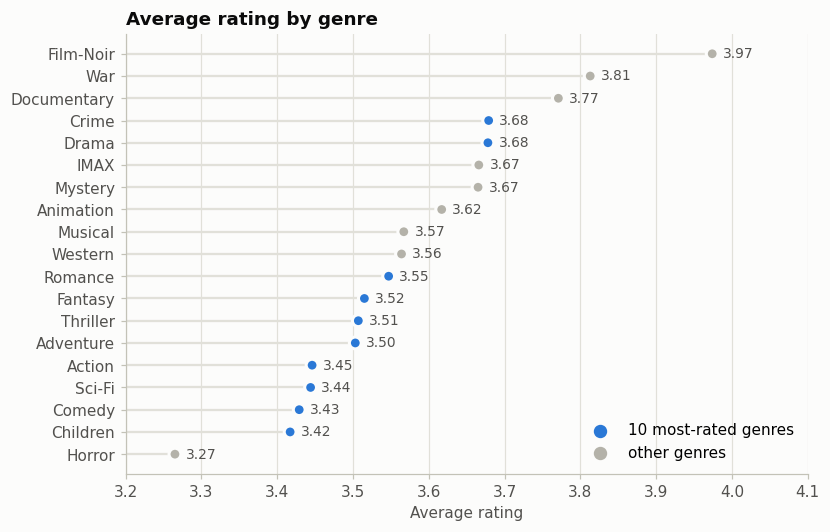

In [4]:
g = genres.sort_values('avg_rating')
colors = [BLUE if top else GRAY for top in g['top_10_by_ratings']]

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.hlines(range(len(g)), 3.2, g['avg_rating'], color=GRID, linewidth=1.5)
ax.scatter(g['avg_rating'], range(len(g)), s=60, c=colors, edgecolors=SURFACE, linewidths=2, zorder=3)
for i, (_, row) in enumerate(g.iterrows()):
    ax.annotate(f"{row['avg_rating']:.2f}", (row['avg_rating'], i), textcoords='offset points', xytext=(7, 0),
                va='center', fontsize=9, color=INK2)
ax.set_yticks(range(len(g)), g['genre'])
ax.set_xlim(3.2, 4.1)
ax.set_xlabel('Average rating')
ax.grid(axis='y', visible=False)
ax.scatter([], [], s=60, c=BLUE, label='10 most-rated genres')
ax.scatter([], [], s=60, c=GRAY, label='other genres')
ax.legend(loc='lower right')
ax.set_title('Average rating by genre')
fig.savefig(FIG_DIR / 'genre_ratings.png')
plt.show()

Among the ten genres with the most ratings, Crime and Drama rate highest; Horror is the lowest-rated genre overall. The very top of the chart belongs to niche genres: Film-Noir and Documentary each have about 1% of the ratings, mostly from people who chose those films deliberately.

## 3. Top movies

Averages over a handful of ratings are noise, so only movies with at least 1,000 ratings in the sample qualify.

In [5]:
sql('''
    SELECT m.title,
           COUNT(*)                AS n_ratings,
           ROUND(AVG(r.rating), 2) AS avg_rating
    FROM ratings AS r
    JOIN movies  AS m USING (movieId)
    GROUP BY r.movieId
    HAVING COUNT(*) >= 1000
    ORDER BY avg_rating DESC
    LIMIT 10
''')

,title,n_ratings,avg_rating
0,"Shawshank Redemption, The (1994)",1599,4.50
1,"Godfather, The (1972)",1042,4.36
2,"Usual Suspects, The (1995)",1146,4.36
3,Schindler's List (1993),1250,4.33
4,Raiders of the Lost Ark (Indiana Jones and the...,1074,4.23
5,Star Wars: Episode IV - A New Hope (1977),1411,4.23
6,American Beauty (1999),1093,4.19
7,"Matrix, The (1999)",1334,4.18
8,Star Wars: Episode V - The Empire Strikes Back...,1130,4.18
9,"Silence of the Lambs, The (1991)",1576,4.17


## 4. Decades

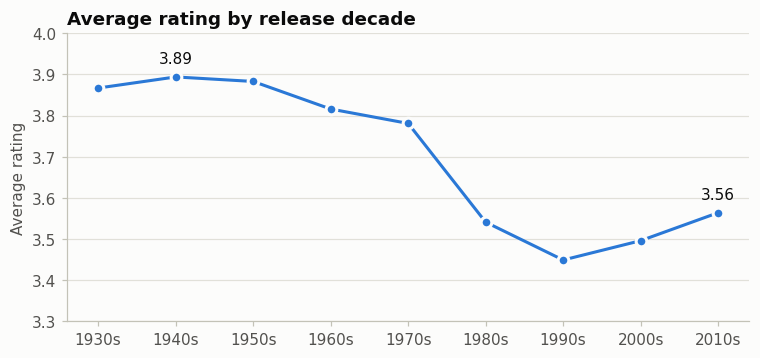

,decade,n_ratings,avg_rating
0,1930,4568,3.867
1,1940,7114,3.894
2,1950,11518,3.883
3,1960,16799,3.816
4,1970,28621,3.781
5,1980,75031,3.541
6,1990,222929,3.449
7,2000,119821,3.496
8,2010,12767,3.564


In [6]:
decades = sql('''
    SELECT CAST(year / 10 AS INTEGER) * 10 AS decade,
           COUNT(*)                        AS n_ratings,
           ROUND(AVG(rating), 3)           AS avg_rating
    FROM ratings
    WHERE year >= 1930
    GROUP BY decade
    ORDER BY decade
''')

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(decades['decade'].astype(str) + 's', decades['avg_rating'], color=BLUE, marker='o', markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=2)
for i in (decades['avg_rating'].idxmax(), len(decades) - 1):
    ax.annotate(f"{decades.loc[i, 'avg_rating']:.2f}", (i, decades.loc[i, 'avg_rating']),
                textcoords='offset points', xytext=(0, 9), ha='center', color=INK)
ax.set_ylim(3.3, 4.0)
ax.set_ylabel('Average rating')
ax.grid(axis='x', visible=False)
ax.set_title('Average rating by release decade')
fig.savefig(FIG_DIR / 'decade_ratings.png')
plt.show()
decades

Films from the 1940s–1950s average about 3.9; films from the 1990s onward, about 3.5. Viewers in 1995–2015 rarely picked a random 1950s film: they watched the ones that were already known to be good. The trend says more about which old films survive than about film quality over time.

In [7]:
con.close()